In [88]:
import pandas as pd 
import numpy as np

In [89]:
data = pd.read_csv("dataset.csv")

In [90]:
df = data.copy()

In [91]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [92]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [93]:
df.shape

(1067371, 8)

In [94]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [95]:
df = df.dropna(subset=['Customer ID'])

In [96]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [97]:
for col in df.columns:
    blank_count =(
        df[col].astype("string").str.strip().eq("").sum()
    )
print(col , ":", blank_count)

Country : 0


In [98]:
df['Customer ID'].duplicated().sum()

818422

In [99]:
df.shape

(824364, 8)

In [100]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [101]:
df.duplicated().sum()

26479

In [102]:
df = df.drop_duplicates()

In [103]:
df.duplicated().sum()

0

In [104]:
df['Customer ID'].nunique()

5942

In [105]:
text_columns = ['StockCode', 'Description', 'Country']

for col in text_columns:
    df[col] = df[col].astype('string').str.strip()
df[text_columns].head()

,StockCode,Description,Country
0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,United Kingdom
1,79323P,PINK CHERRY LIGHTS,United Kingdom
2,79323W,WHITE CHERRY LIGHTS,United Kingdom
3,22041,"RECORD FRAME 7"" SINGLE SIZE",United Kingdom
4,21232,STRAWBERRY CERAMIC TRINKET BOX,United Kingdom


In [106]:
for col in df.columns:
    blank_count = df[col].astype("string").str.strip().eq("").sum()
    print(col, ":", blank_count)

Invoice : 0
StockCode : 0
Description : 0
Quantity : 0
InvoiceDate : 0
Price : 0
Customer ID : 0
Country : 0


In [107]:
df.dtypes

Invoice                object
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate            object
Price                 float64
Customer ID           float64
Country        string[python]
dtype: object

In [108]:
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    errors='coerce'
)

df['Customer ID'] = df['Customer ID'].astype('Int64')

df.dtypes

Invoice                object
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country        string[python]
dtype: object

In [109]:
print("Negative Quantity:",
      (df['Quantity'] < 0).sum())

print("Zero Quantity:",
      (df['Quantity'] == 0).sum())

print("Negative Price:",
      (df['Price'] < 0).sum())

print("Zero Price:",
      (df['Price'] == 0).sum())

Negative Quantity: 18390
Zero Quantity: 0
Negative Price: 0
Zero Price: 70


In [110]:
cancelled = df[
    df['Invoice'].astype(str).str.startswith('C')
]

print("Cancelled Invoice Records:", len(cancelled))

Cancelled Invoice Records: 18390


In [111]:
print("Final Shape:", df.shape)

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Unique Customers:", df['Customer ID'].nunique())


Final Shape: (797885, 8)
Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64
Duplicate Rows: 0
Unique Customers: 5942


In [112]:
df.to_csv(
    "RetailPulse_Cleaned.csv",
    index=False
)

In [113]:
print("Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Invalid Dates:", df['InvoiceDate'].isnull().sum())

print("Unique Customers:", df['Customer ID'].nunique())

Dataset Shape: (797885, 8)
Missing Values: 0
Duplicate Rows: 0
Invalid Dates: 0
Unique Customers: 5942


In [114]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [115]:
sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (10, 5)

In [116]:
df['Revenue'] = df['Quantity'] * df['Price']

df[['Invoice', 'StockCode', 'Quantity',
    'Price', 'Revenue']].head(10)

,Invoice,StockCode,Quantity,Price,Revenue
0,489434,85048,12,6.95,83.4
1,489434,79323P,12,6.75,81.0
2,489434,79323W,12,6.75,81.0
3,489434,22041,48,2.10,100.8
4,489434,21232,24,1.25,30.0
5,489434,22064,24,1.65,39.6
6,489434,21871,24,1.25,30.0
7,489434,21523,10,5.95,59.5
8,489435,22350,12,2.55,30.6
9,489435,22349,12,3.75,45.0


In [117]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df['Year'] = df['InvoiceDate'].dt.year

df['Month'] = df['InvoiceDate'].dt.month

df['Month_Name'] = df['InvoiceDate'].dt.month_name()

df['Day'] = df['InvoiceDate'].dt.day

df['Hour'] = df['InvoiceDate'].dt.hour

In [118]:
sales_df = df[
    (~df['Invoice'].astype(str).str.startswith('C')) &
    (df['Quantity'] > 0) &
    (df['Price'] > 0)
].copy()

In [119]:
total_revenue = sales_df['Revenue'].sum()

print("Total Revenue:", total_revenue)


Total Revenue: 17374804.268000003


In [120]:
total_orders = sales_df['Invoice'].nunique()

print("Total Orders:", total_orders)

Total Orders: 36969


In [121]:
total_quantity = sales_df['Quantity'].sum()

print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 10513952


In [122]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", average_order_value)

Average Order Value: 469.9830741432011


In [123]:
monthly_sales = sales_df.groupby(
    ['Year', 'Month', 'Month_Name']
)['Revenue'].sum().reset_index()

monthly_sales = monthly_sales.sort_values(
    ['Year', 'Month']
)

monthly_sales.head(15)

,Year,Month,Month_Name,Revenue
0,2009,12,December,683504.010
1,2010,1,January,555802.672
2,2010,2,February,504558.956
3,2010,3,March,696978.471
4,2010,4,April,591982.002
5,2010,5,May,597833.380
6,2010,6,June,636371.130
7,2010,7,July,589736.170
8,2010,8,August,602224.600
9,2010,9,September,829013.951


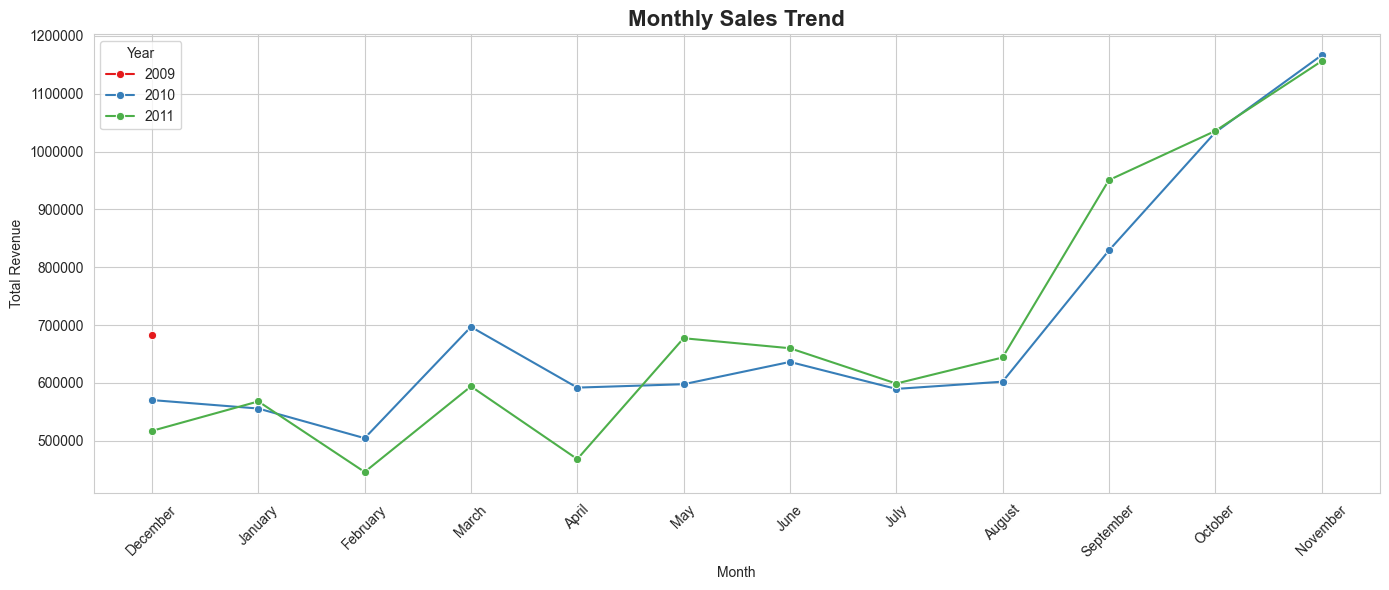

In [124]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x='Month_Name',
    y='Revenue',
    hue='Year',
    marker='o',
    palette='Set1'
)

plt.title('Monthly Sales Trend',
          fontsize=16, fontweight='bold')

plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.legend(title='Year')

plt.ticklabel_format(axis='y', style='plain')

plt.tight_layout()
plt.show()

In [125]:
highest_month = monthly_sales.loc[
    monthly_sales['Revenue'].idxmax()
]

print("Highest Sales Month:",
      highest_month['Month_Name'])

print("Year:",
      highest_month['Year'])

print("Revenue:",
      round(highest_month['Revenue'], 2))

Highest Sales Month: November
Year: 2010
Revenue: 1166460.02


In [126]:
lowest_month = monthly_sales.loc[
    monthly_sales['Revenue'].idxmin()
]

print("Lowest Sales Month:",
      lowest_month['Month_Name'])

print("Year:",
      lowest_month['Year'])

print("Revenue:",
      round(lowest_month['Revenue'], 2))


Lowest Sales Month: February
Year: 2011
Revenue: 446084.92


In [127]:
yearly_sales = sales_df.groupby('Year')['Revenue'].sum().reset_index()

yearly_sales

,Year,Revenue
0,2009,683504.010
1,2010,8374496.094
2,2011,8316804.164


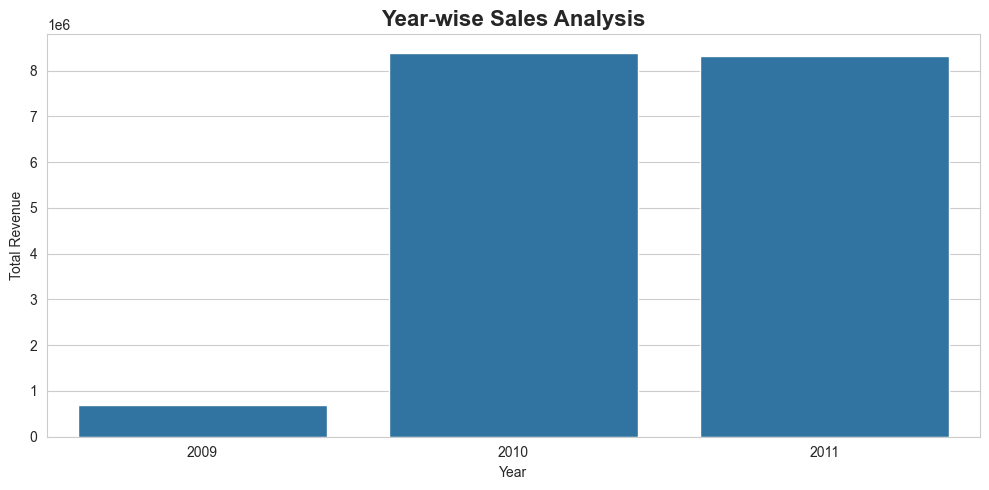

In [128]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_sales,
    x='Year',
    y='Revenue'
)

plt.title('Year-wise Sales Analysis',
          fontsize=16, fontweight='bold')

plt.xlabel('Year')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

In [129]:
yearly_orders = sales_df.groupby('Year')['Invoice'].nunique().reset_index()

yearly_orders.columns = ['Year', 'Total Orders']

yearly_orders

,Year,Total Orders
0,2009,1512
1,2010,18325
2,2011,17132


In [130]:
yearly_quantity = sales_df.groupby('Year')['Quantity'].sum().reset_index()

yearly_quantity.columns = ['Year', 'Total Quantity']

yearly_quantity

,Year,Total Quantity
0,2009,398660
1,2010,5274337
2,2011,4840955


In [131]:
yearly_sales['Growth_Percentage'] = (
    yearly_sales['Revenue'].pct_change() * 100
)

yearly_sales

,Year,Revenue,Growth_Percentage
0,2009,683504.010,NaN
1,2010,8374496.094,1125.229987
2,2011,8316804.164,-0.688900


In [132]:
yearly_report = yearly_sales.merge(
    yearly_orders, on='Year'
)

yearly_report = yearly_report.merge(
    yearly_quantity, on='Year'
)

yearly_report

,Year,Revenue,Growth_Percentage,Total Orders,Total Quantity
0,2009,683504.010,NaN,1512,398660
1,2010,8374496.094,1125.229987,18325,5274337
2,2011,8316804.164,-0.688900,17132,4840955


In [133]:
customer_spending = sales_df.groupby(
    'Customer ID'
).agg(
    Total_Spending=('Revenue', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

customer_spending.head(10)

,Customer ID,Total_Spending,Total_Orders,Total_Quantity
0,12346,77556.46,12,74285
1,12347,4921.53,8,2967
2,12348,2019.40,5,2714
3,12349,4428.69,4,1624
4,12350,334.40,1,197
5,12351,300.93,1,261
6,12352,2849.84,10,724
7,12353,406.76,2,212
8,12354,1079.40,1,530
9,12355,947.61,2,543


In [134]:
average_spending = customer_spending['Total_Spending'].mean()

print("Average Customer Spending:", round(average_spending, 2))

Average Customer Spending: 2955.9


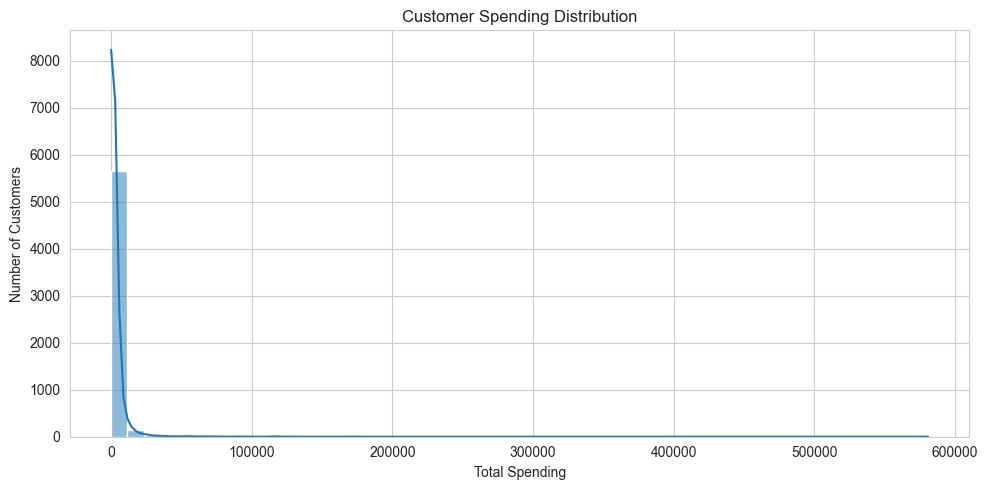

In [135]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_spending,
    x='Total_Spending',
    bins=50,
    kde=True
)

plt.title('Customer Spending Distribution')
plt.xlabel('Total Spending')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()



In [136]:
top_customers = customer_spending.sort_values(
    by='Total_Spending',
    ascending=False
).head(10)

top_customers


,Customer ID,Total_Spending,Total_Orders,Total_Quantity
5692,18102,580987.04,145,181645
2277,14646,528602.52,151,367193
1789,14156,313437.62,156,164325
2538,14911,291420.81,398,147972
5050,17450,244784.25,51,83914
1331,13694,195640.69,143,188201
5109,17511,172132.87,60,117174
4061,16446,168472.50,2,80997
4295,16684,147142.77,55,104810
68,12415,144458.37,28,91447


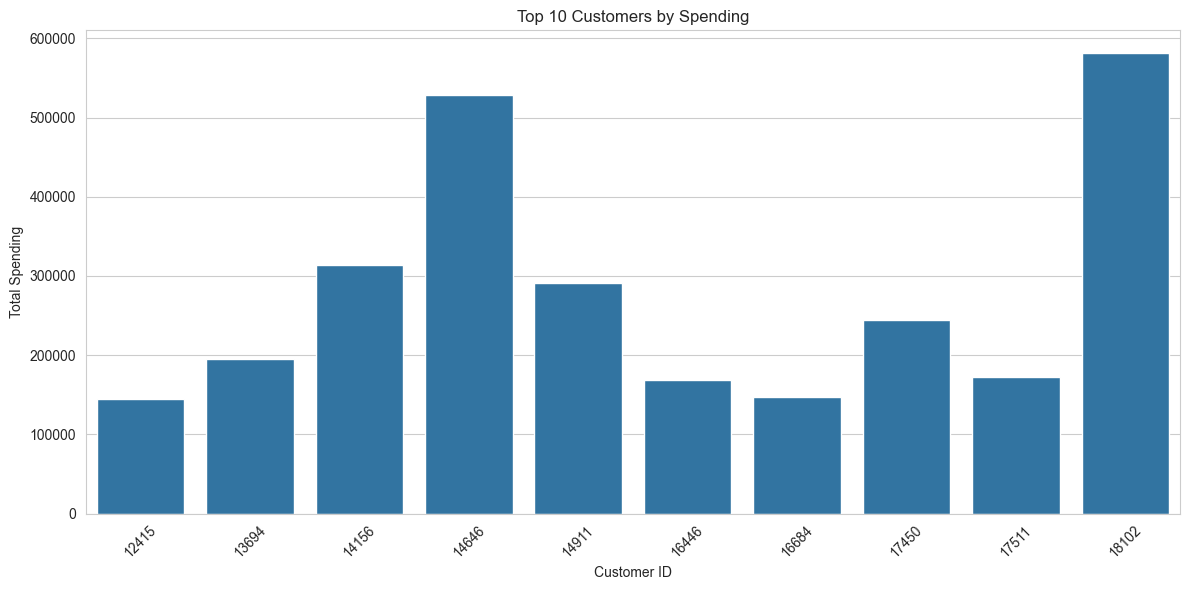

In [137]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customers,
    x='Customer ID',
    y='Total_Spending'
)

plt.title('Top 10 Customers by Spending')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [138]:
print("Total Customers:", customer_spending['Customer ID'].nunique())

print("Average Spending:",
      round(customer_spending['Total_Spending'].mean(), 2))

print("Highest Spending:",
      round(customer_spending['Total_Spending'].max(), 2))

print("Lowest Spending:",
      round(customer_spending['Total_Spending'].min(), 2))

Total Customers: 5878
Average Spending: 2955.9
Highest Spending: 580987.04
Lowest Spending: 2.95


In [139]:
best_customer = customer_spending.loc[
    customer_spending['Total_Spending'].idxmax()
]

print("Best Customer ID:",
      best_customer['Customer ID'])

print("Total Spending:",
      best_customer['Total_Spending'])

print("Total Orders:",
      best_customer['Total_Orders'])

Best Customer ID: 18102.0
Total Spending: 580987.04
Total Orders: 145.0


In [140]:
customer_frequency = sales_df.groupby(
    'Customer ID'
)['Invoice'].nunique().reset_index()

customer_frequency.columns = [
    'Customer ID',
    'Purchase_Frequency'
]

customer_frequency.head(10)

,Customer ID,Purchase_Frequency
0,12346,12
1,12347,8
2,12348,5
3,12349,4
4,12350,1
5,12351,1
6,12352,10
7,12353,2
8,12354,1
9,12355,2


In [141]:
repeat_customers = customer_frequency[
    customer_frequency['Purchase_Frequency'] > 1
]

print("Repeat Customers:", len(repeat_customers))

Repeat Customers: 4255


In [142]:
one_time_customers = customer_frequency[
    customer_frequency['Purchase_Frequency'] == 1
]

print("One-Time Customers:", len(one_time_customers))

One-Time Customers: 1623


In [143]:
total_customers = len(customer_frequency)

repeat_percentage = (
    len(repeat_customers) / total_customers
) * 100

print("Repeat Customer Percentage:",
      round(repeat_percentage, 2), "%")

Repeat Customer Percentage: 72.39 %


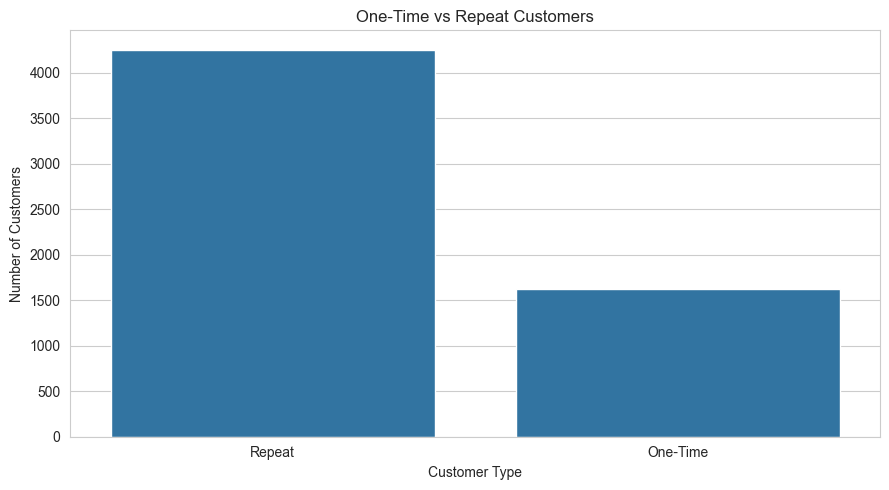

In [144]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x=customer_frequency['Purchase_Frequency'].apply(
        lambda x: 'One-Time' if x == 1 else 'Repeat'
    )
)

plt.title('One-Time vs Repeat Customers')
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

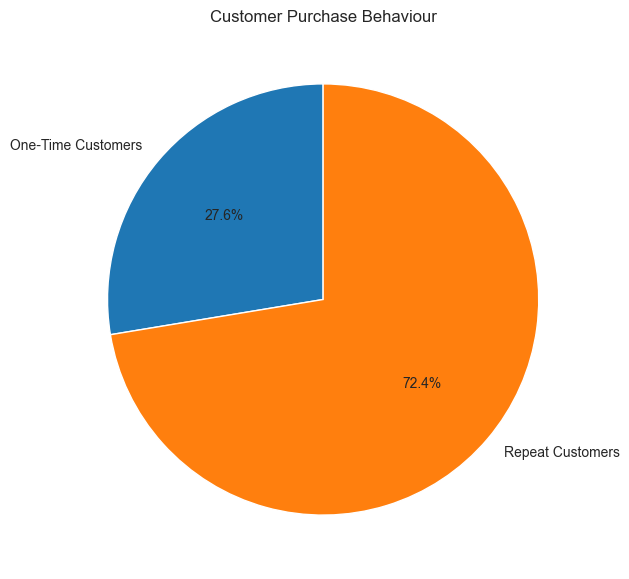

In [145]:
customer_types = [
    len(one_time_customers),
    len(repeat_customers)
]

plt.figure(figsize=(7, 7))

plt.pie(
    customer_types,
    labels=['One-Time Customers', 'Repeat Customers'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Purchase Behaviour')
plt.show()

In [146]:
frequent_customers = customer_frequency.sort_values(
    by='Purchase_Frequency',
    ascending=False
).head(10)

frequent_customers

,Customer ID,Purchase_Frequency
2538,14911,398
400,12748,336
5433,17841,211
2935,15311,208
739,13089,203
2237,14606,192
1789,14156,156
5442,17850,155
2277,14646,151
5692,18102,145


In [147]:
print("Total Customers:", total_customers)

print("Repeat Customers:", len(repeat_customers))

print("One-Time Customers:", len(one_time_customers))

print("Repeat Customer Percentage:",
      round(repeat_percentage, 2), "%")

Total Customers: 5878
Repeat Customers: 4255
One-Time Customers: 1623
Repeat Customer Percentage: 72.39 %


In [148]:
product_sales = sales_df.groupby(
    ['StockCode', 'Description']
).agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Orders=('Invoice', 'nunique')
).reset_index()

product_sales.head(10)

,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
0,10002,INFLATABLE POLITICAL GLOBE,6638.27,8479,297
1,10080,GROOVY CACTUS INFLATABLE,124.61,303,26
2,10109,BENDY COLOUR PENCILS,1.68,4,1
3,10120,DOGGY RUBBER,136.08,648,62
4,10123C,HEARTS WRAPPING TAPE,226.76,628,46
5,10123G,ARMY CAMO WRAPPING TAPE,157.18,2246,12
6,10124A,SPOTS ON RED BOOKCOVER TAPE,24.36,58,18
7,10124G,ARMY CAMO BOOKCOVER TAPE,13.44,32,9
8,10125,MINI FUNKY DESIGN TAPES,1562.70,1970,120
9,10133,COLOURING PENCILS BROWN TUBE,1910.79,3307,203


In [149]:
top_products = product_sales.sort_values(
    by='Total_Quantity',
    ascending=False
).head(10)

top_products

,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
4006,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,24098.03,105185,920
4723,85123A,WHITE HANGING HEART T-LIGHT HOLDER,247048.01,91757,4888
3263,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
4429,84879,ASSORTED COLOUR BIRD ORNAMENT,124351.86,78234,2652
2761,23166,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916,195
4698,85099B,JUMBO BAG RED RETROSPOT,134307.44,74224,2612
114,17003,BROCADE RING PURSE,14640.96,70082,387
1347,21977,PACK OF 60 PINK PAISLEY CAKE CASES,26407.35,54592,1578
4568,84991,60 TEATIME FAIRY CAKE CASES,25785.92,52828,1765
655,21212,PACK OF 72 RETRO SPOT CAKE CASES,21838.23,45129,1160


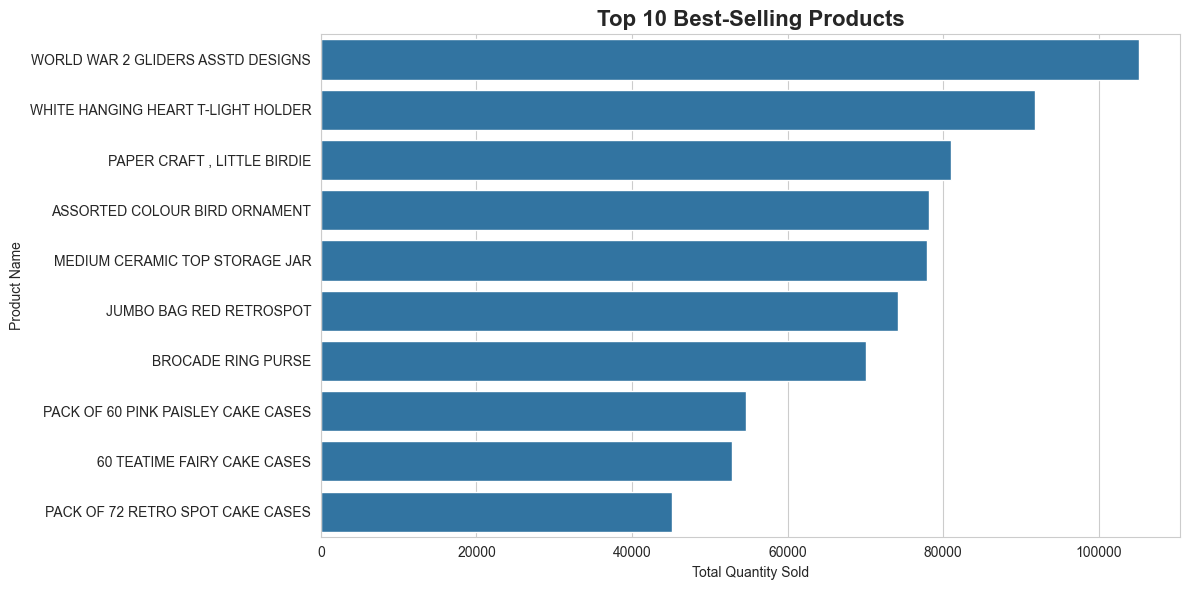

In [150]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x='Total_Quantity',
    y='Description'
)

plt.title('Top 10 Best-Selling Products',
          fontsize=16, fontweight='bold')

plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [151]:
top_revenue_products = product_sales.sort_values(
    by='Total_Revenue',
    ascending=False
).head(10)

top_revenue_products

,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
1846,22423,REGENCY CAKESTAND 3 TIER,277656.25,24124,3317
4723,85123A,WHITE HANGING HEART T-LIGHT HOLDER,247048.01,91757,4888
3263,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
5280,M,Manual,151777.67,9384,620
4698,85099B,JUMBO BAG RED RETROSPOT,134307.44,74224,2612
5282,POST,POSTAGE,124648.04,5235,1803
4429,84879,ASSORTED COLOUR BIRD ORNAMENT,124351.86,78234,2652
3606,47566,PARTY BUNTING,103283.38,23460,2077
2761,23166,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,77916,195
1437,22086,PAPER CHAIN KIT 50'S CHRISTMAS,76598.18,28380,1691


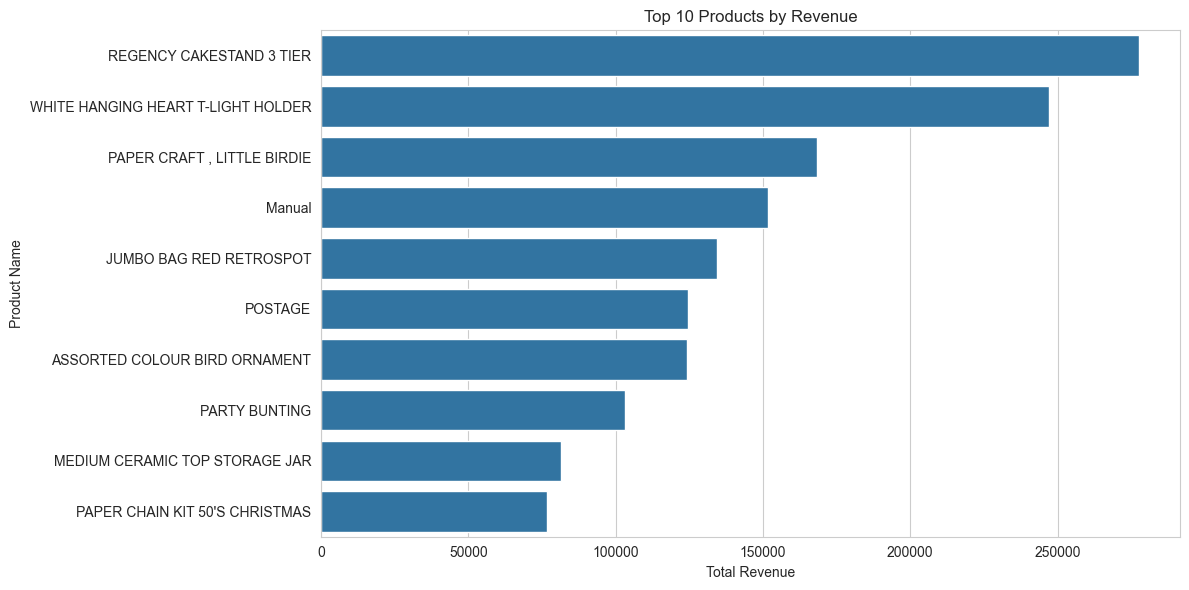

In [152]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_revenue_products,
    x='Total_Revenue',
    y='Description'
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [153]:
low_products = product_sales.sort_values(
    by='Total_Revenue',
    ascending=True
).head(10)

low_products

,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
5281,PADS,PADS TO MATCH ALL CUSHIONS,0.017,17,17
3386,35930,PINK HEART CHRISTMAS DECORATION,0.380,1,1
4015,84205C,HAPPY BIRTHDAY GINGER CAT CARD,0.380,2,1
2995,23366,SET 12 COLOURING PENCILS DOILEY,0.650,1,1
4017,84206B,CAT W SUNGLASSES BLANK CARD,0.760,4,1
273,20721,OWLS CHARLOTTE BAG,0.850,1,1
4018,84206B,CAT WITH SUNGLASSES BLANK CARD,0.950,5,1
5285,TEST002,This is a test product.,1.000,1,1
3001,23370,SET 36 COLOURING PENCILS DOILEY,1.250,1,1
4388,84845A,HOLLYHOCK SQUARE HANDY TIN,1.250,1,1


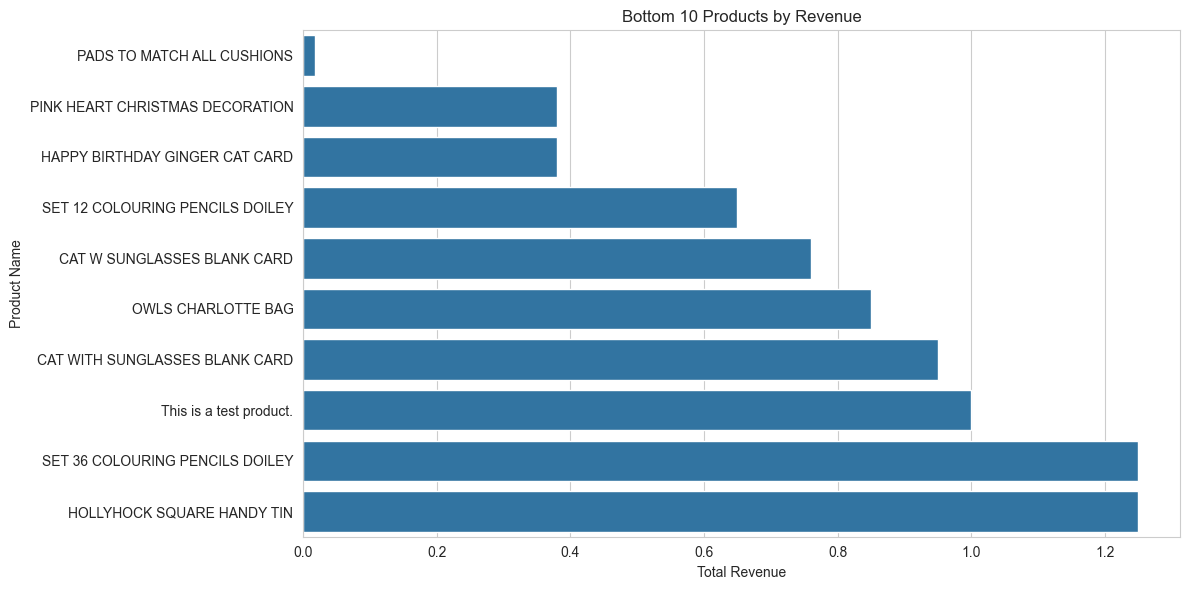

In [154]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=low_products,
    x='Total_Revenue',
    y='Description'
)

plt.title('Bottom 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [155]:
print("Total Products:",
      product_sales['StockCode'].nunique())

print("Total Product Revenue:",
      round(product_sales['Total_Revenue'].sum(), 2))

print("Total Quantity Sold:",
      product_sales['Total_Quantity'].sum())

print("Highest Product Revenue:",
      round(product_sales['Total_Revenue'].max(), 2))

Total Products: 4631
Total Product Revenue: 17374804.27
Total Quantity Sold: 10513952
Highest Product Revenue: 277656.25


In [156]:
country_sales = sales_df.groupby('Country').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Total_Customers=('Customer ID', 'nunique')
).reset_index()

country_sales.head(10)

,Country,Total_Revenue,Total_Orders,Total_Quantity,Total_Customers
0,Australia,169283.46,95,103759,15
1,Austria,23613.01,45,11578,13
2,Bahrain,1354.37,4,755,2
3,Belgium,65387.82,149,34768,29
4,Brazil,1411.87,2,545,2
5,Canada,4883.04,8,3657,5
6,Channel Islands,44623.33,55,21396,13
7,Cyprus,24849.95,37,10950,11
8,Czech Republic,826.74,2,671,1
9,Denmark,68580.69,43,237471,12


In [157]:
top_countries = country_sales.sort_values(
    by='Total_Revenue',
    ascending=False
).head(10)

top_countries

,Country,Total_Revenue,Total_Orders,Total_Quantity,Total_Customers
38,United Kingdom,1.438923e+07,33541,8532411,5350
10,EIRE,6.165705e+05,567,318021,5
24,Netherlands,5.540381e+05,228,383879,22
14,Germany,4.250197e+05,789,225154,107
13,France,3.487690e+05,614,270288,95
0,Australia,1.692835e+05,95,103759,15
32,Spain,1.083325e+05,154,50307,41
34,Switzerland,1.000619e+05,90,52227,22
33,Sweden,9.151582e+04,104,88495,19
9,Denmark,6.858069e+04,43,237471,12


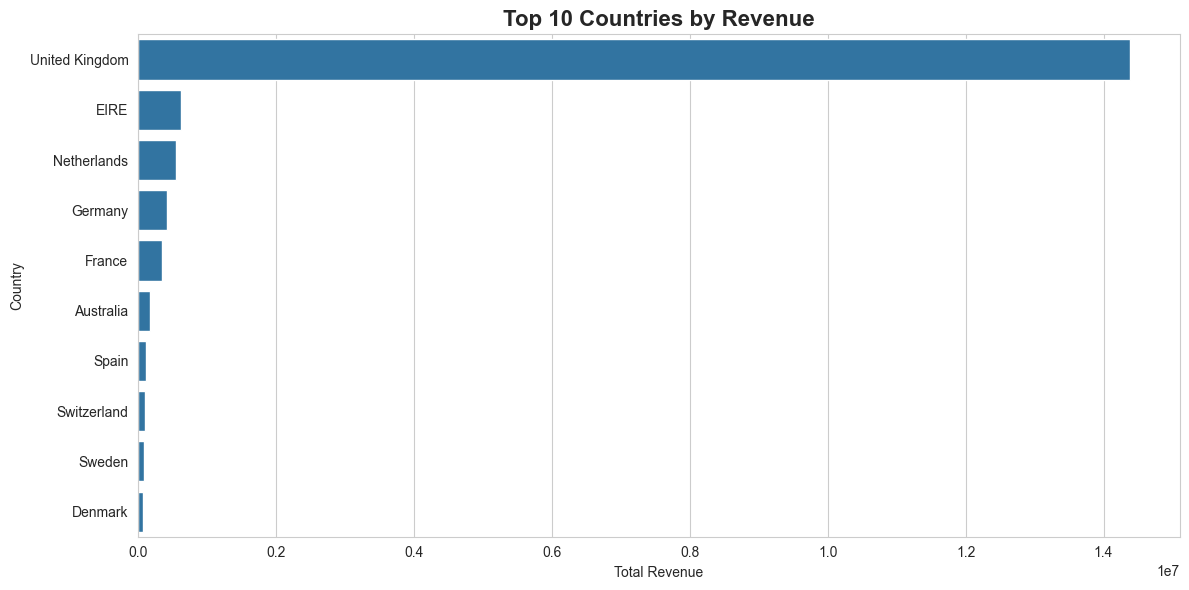

In [158]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Total_Revenue',
    y='Country'
)

plt.title('Top 10 Countries by Revenue',
          fontsize=16, fontweight='bold')

plt.xlabel('Total Revenue')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

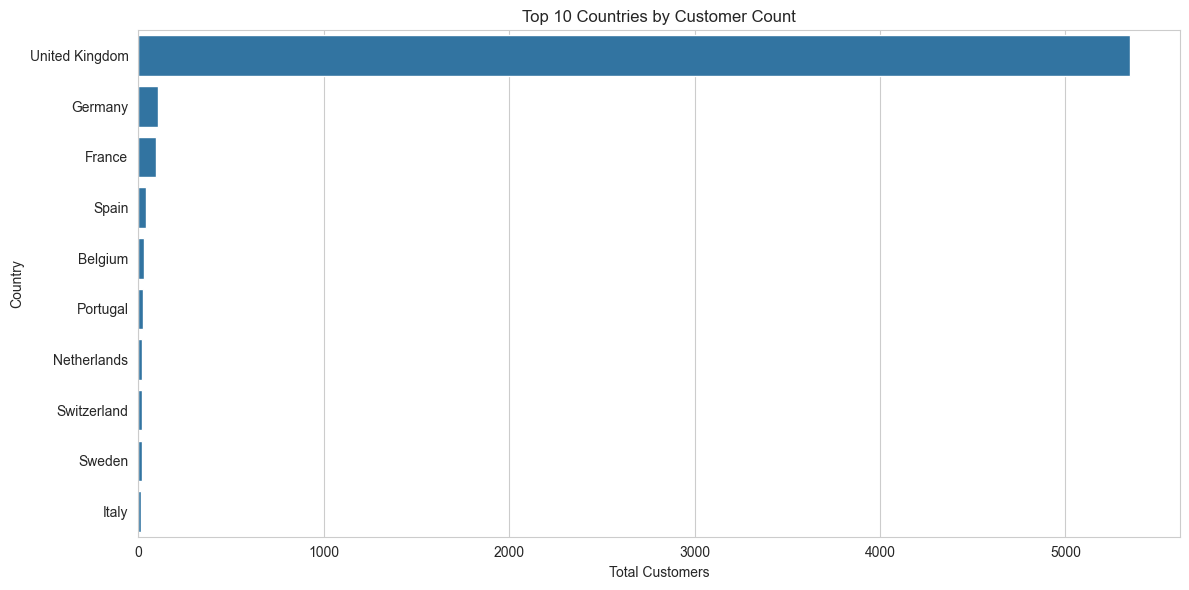

In [159]:
top_customer_countries = country_sales.sort_values(
    by='Total_Customers',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_customer_countries,
    x='Total_Customers',
    y='Country'
)

plt.title('Top 10 Countries by Customer Count')
plt.xlabel('Total Customers')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [160]:
print("Total Countries:",
      country_sales['Country'].nunique())

print("Highest Revenue Country:",
      top_countries.iloc[0]['Country'])

print("Highest Revenue:",
      round(top_countries.iloc[0]['Total_Revenue'], 2))

print("Total Revenue:",
      round(country_sales['Total_Revenue'].sum(), 2))

Total Countries: 41
Highest Revenue Country: United Kingdom
Highest Revenue: 14389234.92
Total Revenue: 17374804.27


In [161]:
correlation_df = sales_df[
    ['Quantity', 'Price', 'Revenue']
]

correlation_df.head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [162]:
correlation_matrix = correlation_df.corr()

correlation_matrix

,Quantity,Price,Revenue
Quantity,1.000000,-0.004880,0.827162
Price,-0.004880,1.000000,0.135984
Revenue,0.827162,0.135984,1.000000


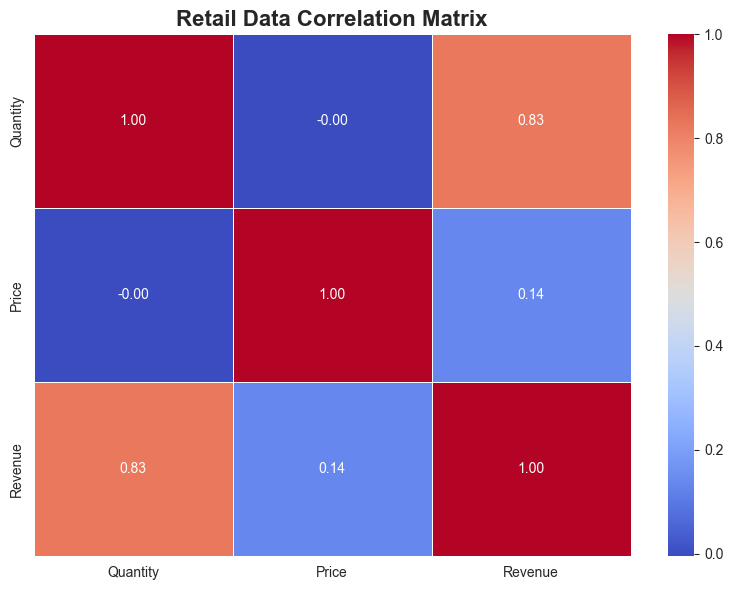

In [163]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Retail Data Correlation Matrix',
          fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

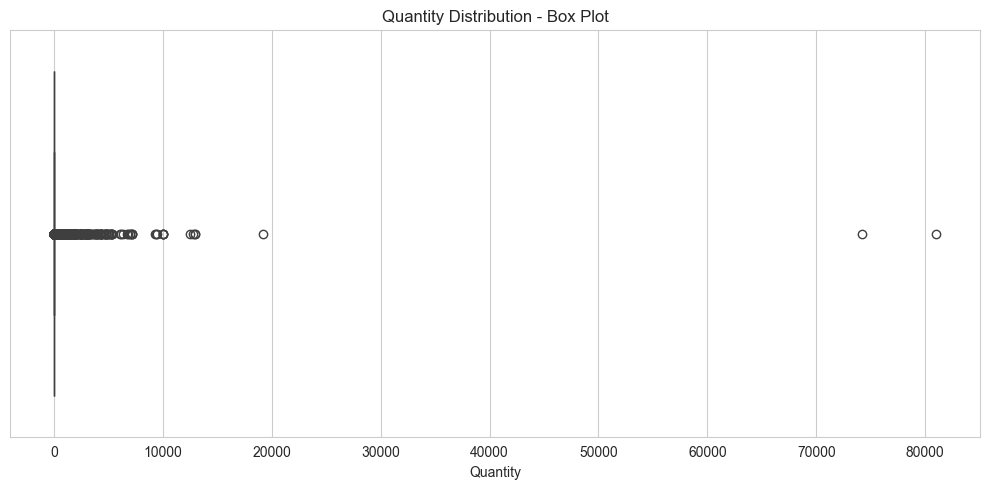

In [164]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=sales_df['Quantity'])

plt.title('Quantity Distribution - Box Plot')
plt.xlabel('Quantity')

plt.tight_layout()
plt.show()

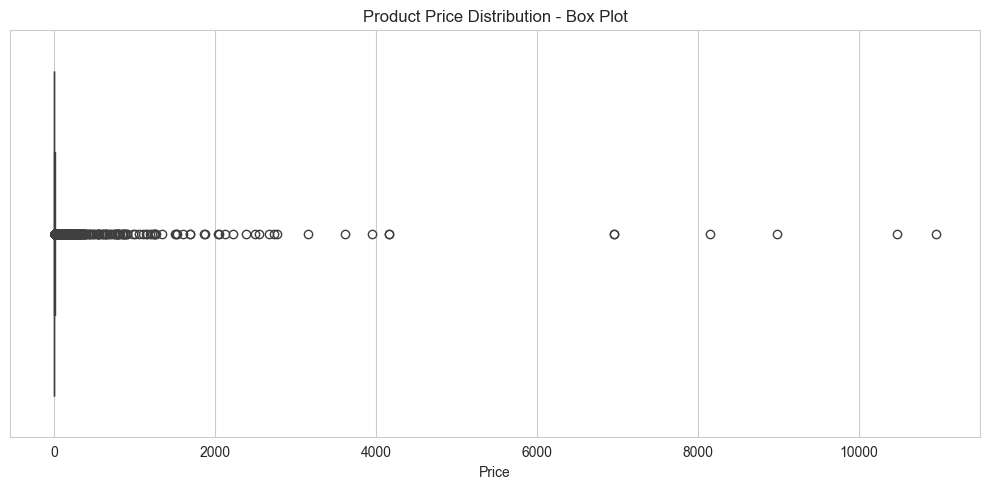

In [165]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=sales_df['Price'])

plt.title('Product Price Distribution - Box Plot')
plt.xlabel('Price')

plt.tight_layout()
plt.show()

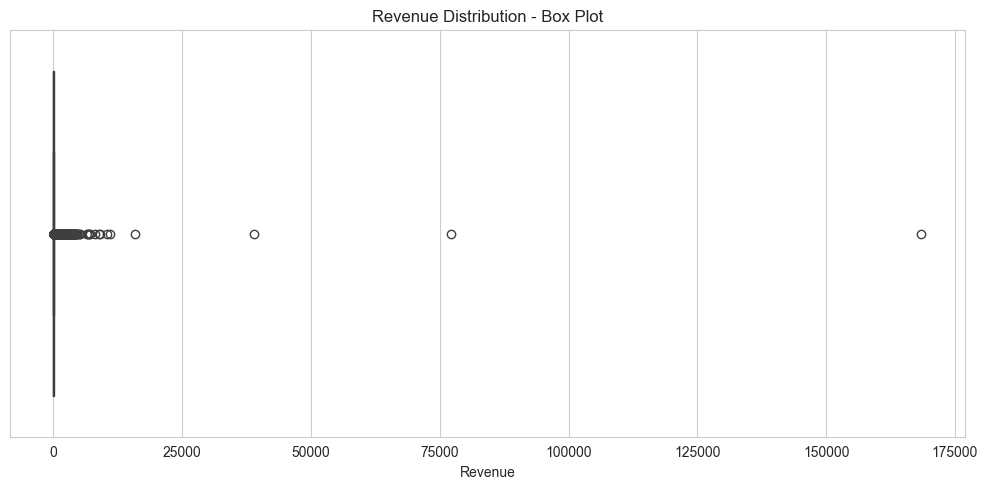

In [166]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=sales_df['Revenue'])

plt.title('Revenue Distribution - Box Plot')
plt.xlabel('Revenue')

plt.tight_layout()
plt.show()

In [167]:
print("Total Revenue:", round(sales_df['Revenue'].sum(), 2))

print("Total Orders:", sales_df['Invoice'].nunique())

print("Total Quantity Sold:", sales_df['Quantity'].sum())

Total Revenue: 17374804.27
Total Orders: 36969
Total Quantity Sold: 10513952


In [168]:
print("Total Customers:", customer_spending['Customer ID'].nunique())

print("Average Customer Spending:",
      round(customer_spending['Total_Spending'].mean(), 2))

print("Top Customer Spending:",
      round(customer_spending['Total_Spending'].max(), 2))

print("Repeat Customers:", len(repeat_customers))

Total Customers: 5878
Average Customer Spending: 2955.9
Top Customer Spending: 580987.04
Repeat Customers: 4255


In [169]:
print("Total Products:", product_sales['StockCode'].nunique())

print("Best Selling Product:")

print(top_products[['Description', 'Total_Quantity']].head(5))

Total Products: 4631
Best Selling Product:
                             Description  Total_Quantity
4006   WORLD WAR 2 GLIDERS ASSTD DESIGNS          105185
4723  WHITE HANGING HEART T-LIGHT HOLDER           91757
3263         PAPER CRAFT , LITTLE BIRDIE           80995
4429       ASSORTED COLOUR BIRD ORNAMENT           78234
2761      MEDIUM CERAMIC TOP STORAGE JAR           77916


In [170]:
print("Total Countries:", country_sales['Country'].nunique())

print("Top 5 Countries by Revenue:")

print(
    country_sales.sort_values(
        'Total_Revenue',
        ascending=False
    )[['Country', 'Total_Revenue']].head(5)
)

Total Countries: 41
Top 5 Countries by Revenue:
           Country  Total_Revenue
38  United Kingdom   1.438923e+07
10            EIRE   6.165705e+05
24     Netherlands   5.540381e+05
14         Germany   4.250197e+05
13          France   3.487690e+05


In [171]:
eda_summary = {
    'Total Revenue': sales_df['Revenue'].sum(),
    'Total Orders': sales_df['Invoice'].nunique(),
    'Total Customers': customer_spending['Customer ID'].nunique(),
    'Total Products': product_sales['StockCode'].nunique(),
    'Total Countries': country_sales['Country'].nunique(),
    'Repeat Customers': len(repeat_customers)
}

eda_report = pd.DataFrame(
    eda_summary.items(),
    columns=['Metric', 'Value']
)

eda_report

,Metric,Value
0,Total Revenue,1.737480e+07
1,Total Orders,3.696900e+04
2,Total Customers,5.878000e+03
3,Total Products,4.631000e+03
4,Total Countries,4.100000e+01
5,Repeat Customers,4.255000e+03


In [172]:
# Numerical columns statistics
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue,Year,Month,Day,Hour
count,797885.000000,797885,797885.000000,797885.0,797885.000000,797885.000000,797885.000000,797885.000000,797885.000000
mean,12.602980,2011-01-02 13:17:34.141160704,3.702732,15313.062777,20.416465,2010.431108,7.411434,15.387388,12.801001
min,-80995.000000,2009-12-01 07:45:00,0.000000,12346.0,-168469.600000,2009.000000,1.000000,1.000000,6.000000
25%,2.000000,2010-07-02 09:47:00,1.250000,13964.0,4.350000,2010.000000,5.000000,8.000000,11.000000
50%,5.000000,2010-12-02 12:33:00,1.950000,15228.0,11.700000,2010.000000,8.000000,15.000000,13.000000
75%,12.000000,2011-07-31 15:50:00,3.750000,16788.0,19.500000,2011.000000,10.000000,23.000000,14.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.0,168469.600000,2011.000000,12.000000,31.000000,21.000000
std,191.670371,NaN,71.392549,1696.466663,313.518824,0.568904,3.424495,8.658264,2.306720


In [174]:
# Categorical columns statistics
df.describe(include='object')

,Invoice,Month_Name
count,797885,797885
unique,44876,12
top,576339,November
freq,542,124313


In [175]:
for col in df.columns:
    blank_count = df[col].astype("string").str.strip().eq("").sum()
    print(col, ":", blank_count)

Invoice : 0
StockCode : 0
Description : 0
Quantity : 0
InvoiceDate : 0
Price : 0
Customer ID : 0
Country : 0
Revenue : 0
Year : 0
Month : 0
Month_Name : 0
Day : 0
Hour : 0


In [176]:
# Check non-standard products
sales_df[
    sales_df['Description'].str.contains(
        'Manual|POSTAGE', case=False, na=False
    )
][['StockCode', 'Description']].drop_duplicates().head(20)

,StockCode,Description
89,POST,POSTAGE
11310,M,Manual
842968,DOT,DOTCOM POSTAGE


In [177]:
# Remove non-standard products for product analysis
normal_products = sales_df[
    ~sales_df['Description'].str.contains(
        'Manual|POSTAGE', case=False, na=False
    )
].copy()

print("Total Records:", len(normal_products))
print("Total Products:", normal_products['StockCode'].nunique())

Total Records: 776925
Total Products: 4628


In [178]:
# Business Insights

# 1. Total Revenue
print("Total Revenue:", sales_df['Revenue'].sum())

# 2. Total Orders
print("Total Orders:", sales_df['Invoice'].nunique())

# 3. Top Country
country_revenue = sales_df.groupby('Country')['Revenue'].sum()
print("Top Country:", country_revenue.idxmax())

# 4. Top Product
product_revenue = normal_products.groupby(
    'Description'
)['Revenue'].sum()

print("Top Product:", product_revenue.idxmax())

# 5. Total Customers
print("Total Customers:", sales_df['Customer ID'].nunique())

# 6. Average Customer Spending
customer_total = sales_df.groupby('Customer ID')['Revenue'].sum()
print("Average Customer Spending:", customer_total.mean())

Total Revenue: 17374804.268000003
Total Orders: 36969
Top Country: United Kingdom
Top Product: REGENCY CAKESTAND 3 TIER
Total Customers: 5878
Average Customer Spending: 2955.9040945899965


Feature Engineering & Data Preprocessing

In [179]:
# Step 1: RFM Feature Engineering

# Reference date
analysis_date = sales_df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM
rfm = sales_df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (analysis_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# Display RFM dataset
rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [181]:
print("Total Customers:", len(rfm))
print("\nRFM Dataset Shape:", rfm.shape)

rfm.describe()

Total Customers: 5878

RFM Dataset Shape: (5878, 4)


,Customer ID,Recency,Frequency,Monetary
count,5878.0,5878.000000,5878.000000,5878.000000
mean,15315.313542,201.331916,6.289384,2955.904095
std,1715.572666,209.338707,13.009406,14440.852688
min,12346.0,1.000000,1.000000,2.950000
25%,13833.25,26.000000,1.000000,342.280000
50%,15314.5,96.000000,3.000000,867.740000
75%,16797.75,380.000000,7.000000,2248.305000
max,18287.0,739.000000,398.000000,580987.040000


In [183]:
# Step 2: RFM Data Validation

print("Missing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Rows:", rfm.duplicated().sum())

print("\nDuplicate Customer IDs:",
      rfm['Customer ID'].duplicated().sum())

print("\nInvalid Values:")
print("Recency <= 0:", (rfm['Recency'] <= 0).sum())
print("Frequency <= 0:", (rfm['Frequency'] <= 0).sum())
print("Monetary <= 0:", (rfm['Monetary'] <= 0).sum())

Missing Values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

Duplicate Rows: 0

Duplicate Customer IDs: 0

Invalid Values:
Recency <= 0: 0
Frequency <= 0: 0
Monetary <= 0: 0


In [184]:
# Step 3: Outlier Detection using IQR

for col in ['Recency', 'Frequency', 'Monetary']:

    Q1 = rfm[col].quantile(0.25)
    Q3 = rfm[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = rfm[
        (rfm[col] < lower_limit) |
        (rfm[col] > upper_limit)
    ]

    print(col, "Outliers:", len(outliers))

Recency Outliers: 0
Frequency Outliers: 427
Monetary Outliers: 633


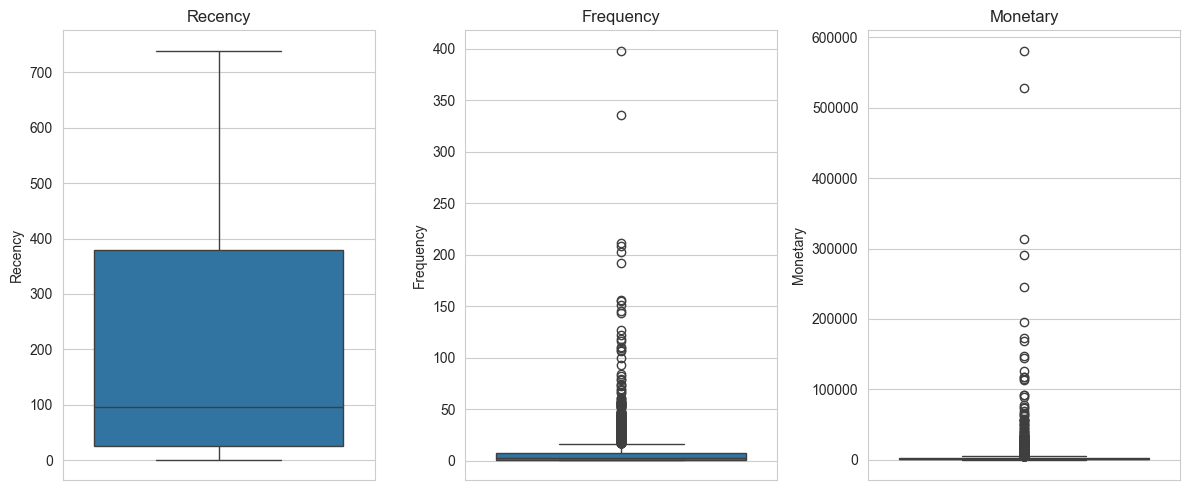

In [185]:
# Step 4: Boxplot for RFM Features

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

for i, col in enumerate(['Recency', 'Frequency', 'Monetary'], 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=rfm[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
# Step 5: Feature Transformation
rfm_transformed = rfm.copy()
rfm_transformed['Frequency'] = np.log1p(
    rfm_transformed['Frequency']
)
rfm_transformed['Monetary'] = np.log1p(
    rfm_transformed['Monetary']
)
rfm_transformed.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,326,2.564949,11.258774
1,12347,2,2.197225,8.501578
2,12348,75,1.791759,7.611051
3,12349,19,1.609438,8.396085
4,12350,310,0.693147,5.815324


In [187]:
rfm_transformed[['Recency', 'Frequency', 'Monetary']].skew()

Recency      0.887198
Frequency    1.001471
Monetary     0.269125
dtype: float64

In [189]:
# Step 6: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = rfm_transformed.copy()

features = ['Recency', 'Frequency', 'Monetary']

rfm_scaled[features] = scaler.fit_transform(
    rfm_scaled[features]
)

rfm_scaled.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,0.595584,1.254496,3.206219
1,12347,-0.952279,0.800166,1.215993
2,12348,-0.603532,0.299207,0.573185
3,12349,-0.871064,0.073946,1.139846
4,12350,0.519146,-1.058146,-0.723024


In [190]:
print("Mean:")
print(rfm_scaled[features].mean())

print("\nStandard Deviation:")
print(rfm_scaled[features].std())

Mean:
Recency     -4.230860e-17
Frequency    2.381370e-16
Monetary     3.771510e-16
dtype: float64

Standard Deviation:
Recency      1.000085
Frequency    1.000085
Monetary     1.000085
dtype: float64


In [191]:
# Step 7: Final ML Dataset

ml_dataset = rfm_scaled[
    ['Customer ID', 'Recency', 'Frequency', 'Monetary']
].copy()

print("Final Dataset Shape:", ml_dataset.shape)

ml_dataset.head()

Final Dataset Shape: (5878, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,0.595584,1.254496,3.206219
1,12347,-0.952279,0.800166,1.215993
2,12348,-0.603532,0.299207,0.573185
3,12349,-0.871064,0.073946,1.139846
4,12350,0.519146,-1.058146,-0.723024


In [192]:
print("Missing Values:")
print(ml_dataset.isnull().sum())

print("\nDuplicate Rows:", ml_dataset.duplicated().sum())

Missing Values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

Duplicate Rows: 0


In [194]:
# Save Final ML Dataset

ml_dataset.to_csv(
    'customer_rfm_final.csv',
    index=False
)

print("Final ML Dataset Saved Successfully!")

Final ML Dataset Saved Successfully!


Customer Segmentation using Machine Learning.

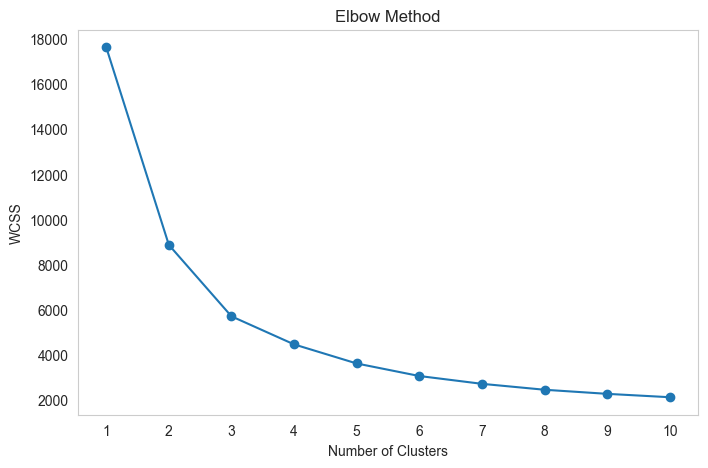

In [195]:
# Phase 5 - Step 1: Elbow Method

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = rfm_scaled[['Recency', 'Frequency', 'Monetary']]

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [196]:
# Step 2: Silhouette Score

from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(X, labels)

    silhouette_scores.append(score)

    print("Clusters:", k, "Silhouette Score:", score)

Clusters: 2 Silhouette Score: 0.41868102005168756
Clusters: 3 Silhouette Score: 0.4009982034076402
Clusters: 4 Silhouette Score: 0.3616115295986692
Clusters: 5 Silhouette Score: 0.36641659978013286
Clusters: 6 Silhouette Score: 0.3469432080383117


In [197]:
# Step 3: Compare K=2 and K=3

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    print(f"\nCluster Distribution for K={k}")

    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )


Cluster Distribution for K=2
0    3179
1    2699
Name: count, dtype: int64

Cluster Distribution for K=3
0    1840
1    1675
2    2363
Name: count, dtype: int64


In [198]:
    # Step 4: K-Means Clustering

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
rfm['Cluster'] = kmeans.fit_predict(X)

# Check cluster distribution
print(rfm['Cluster'].value_counts().sort_index())

Cluster
0    1840
1    1675
2    2363
Name: count, dtype: int64


In [199]:
ml_dataset['Cluster'] = rfm['Cluster'].values

ml_dataset.head()

,Customer ID,Recency,Frequency,Monetary,Cluster
0,12346,0.595584,1.254496,3.206219,1
1,12347,-0.952279,0.800166,1.215993,1
2,12348,-0.603532,0.299207,0.573185,2
3,12349,-0.871064,0.073946,1.139846,1
4,12350,0.519146,-1.058146,-0.723024,0


In [200]:
# Step 5: Customer Cluster Analysis

cluster_analysis = rfm.groupby('Cluster').agg(
    Total_Customers=('Customer ID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean')
).round(2)

cluster_analysis

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,1840,472.95,1.79,555.30
1,1675,57.29,15.95,8561.95
2,2363,91.94,2.94,851.37


In [201]:
# Step 6: Assign Customer Segment Names

segment_names = {
    0: 'Inactive Customers',
    1: 'High-Value Customers',
    2: 'Occasional Customers'
}

rfm['Customer_Segment'] = rfm['Cluster'].map(segment_names)

# Add segment names to final dataset
ml_dataset['Customer_Segment'] = rfm['Customer_Segment'].values

# Check results
ml_dataset[['Customer ID', 'Cluster', 'Customer_Segment']].head(10)

,Customer ID,Cluster,Customer_Segment
0,12346,1,High-Value Customers
1,12347,1,High-Value Customers
2,12348,2,Occasional Customers
3,12349,1,High-Value Customers
4,12350,0,Inactive Customers
5,12351,0,Inactive Customers
6,12352,1,High-Value Customers
7,12353,2,Occasional Customers
8,12354,2,Occasional Customers
9,12355,2,Occasional Customers


In [202]:
print(
    ml_dataset['Customer_Segment'].value_counts()
)

Customer_Segment
Occasional Customers    2363
Inactive Customers      1840
High-Value Customers    1675
Name: count, dtype: int64


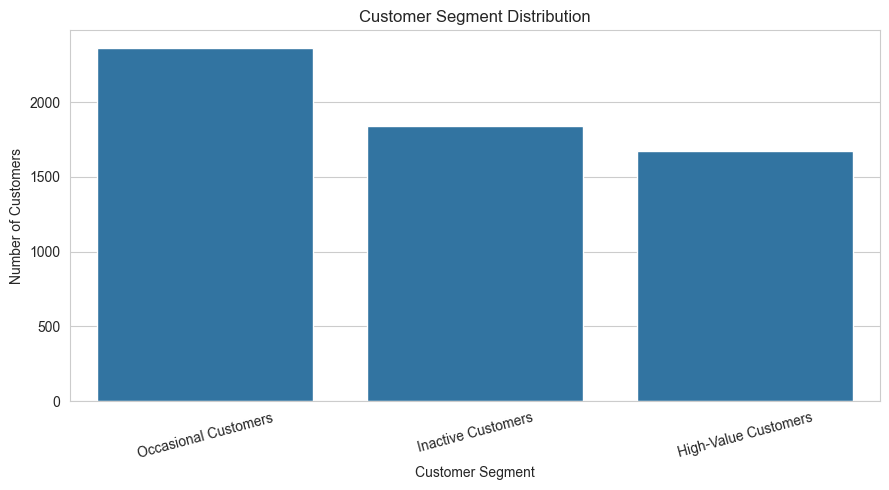

In [203]:
# Step 7: Customer Segment Visualization

plt.figure(figsize=(9, 5))

sns.countplot(
    data=ml_dataset,
    x='Customer_Segment',
    order=ml_dataset['Customer_Segment'].value_counts().index
)

plt.title('Customer Segment Distribution')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

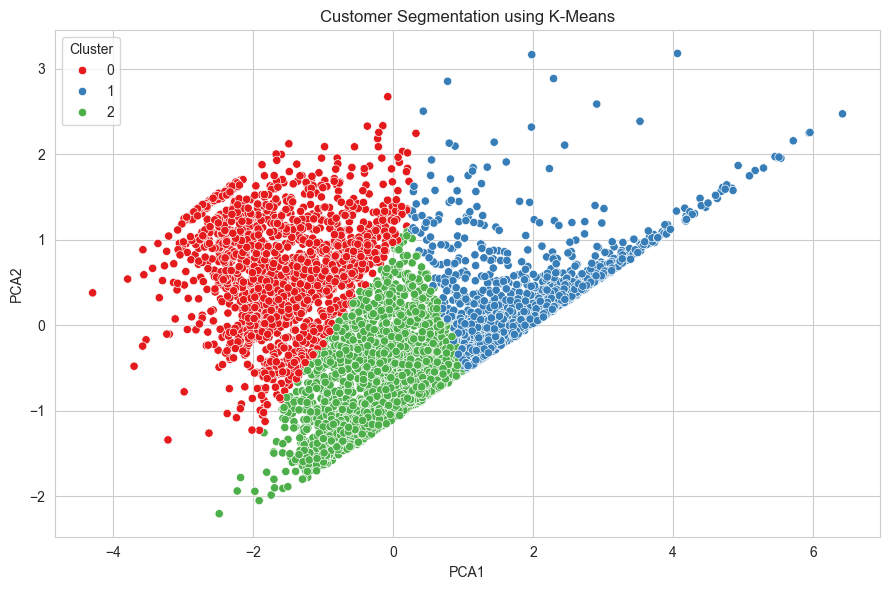

In [205]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PCA1', 'PCA2']
)

pca_df['Cluster'] = rfm['Cluster'].values

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1'
)

plt.title('Customer Segmentation using K-Means')
plt.tight_layout()
plt.show()

In [206]:
# Save Final Customer Segmentation Dataset

ml_dataset.to_csv(
    'customer_segmentation_final.csv',
    index=False
)

print("Customer Segmentation Dataset Saved Successfully!")

Customer Segmentation Dataset Saved Successfully!


Model Evaluation, Interpretation & Project Conclusion.

In [207]:
# Phase 6 - Step 1: Model Evaluation

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Actual cluster labels
labels = rfm['Cluster']

# Evaluation metrics
sil_score = silhouette_score(X, labels)

db_score = davies_bouldin_score(X, labels)

ch_score = calinski_harabasz_score(X, labels)

print("Model Evaluation Results")

print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Score:", round(db_score, 4))
print("Calinski-Harabasz Score:", round(ch_score, 2))

Model Evaluation Results
Silhouette Score: 0.401
Davies-Bouldin Score: 0.8726
Calinski-Harabasz Score: 6124.9


In [208]:
# Phase 6 - Step 2: Compare K=2 and K=3

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X)

    print(f"\nEvaluation for K={k}")

    print("Silhouette:",
          round(silhouette_score(X, cluster_labels), 4))

    print("Davies-Bouldin:",
          round(davies_bouldin_score(X, cluster_labels), 4))

    print("Calinski-Harabasz:",
          round(calinski_harabasz_score(X, cluster_labels), 2))


Evaluation for K=2
Silhouette: 0.4187
Davies-Bouldin: 0.8904
Calinski-Harabasz: 5791.78

Evaluation for K=3
Silhouette: 0.401
Davies-Bouldin: 0.8726
Calinski-Harabasz: 6124.9


In [209]:
# Phase 6 - Step 3: Final Model Summary

print("Final Model: K-Means Clustering")
print("Optimal Clusters: 3")

print("\nCluster Distribution:")
print(ml_dataset['Customer_Segment'].value_counts())

print("\nFinal Evaluation Metrics:")
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Score:", round(db_score, 4))
print("Calinski-Harabasz Score:", round(ch_score, 2))

Final Model: K-Means Clustering
Optimal Clusters: 3

Cluster Distribution:
Customer_Segment
Occasional Customers    2363
Inactive Customers      1840
High-Value Customers    1675
Name: count, dtype: int64

Final Evaluation Metrics:
Silhouette Score: 0.401
Davies-Bouldin Score: 0.8726
Calinski-Harabasz Score: 6124.9


Monthly Sales Data:
        Date  Actual_Revenue
0 2009-12-01      660125.100
1 2010-01-01      530436.512
2 2010-02-01      487596.426
3 2010-03-01      633419.311
4 2010-04-01      558007.832

MODEL EVALUATION
MAE: 356146.83
RMSE: 361260.02
MAPE: 58.01 %

NEXT 3 MONTHS SALES FORECAST
        Date  Predicted_Revenue
0 2012-01-01      751967.928946
1 2012-02-01      760198.389409
2 2012-03-01      768428.849871

Total Predicted Revenue: 2280595.17


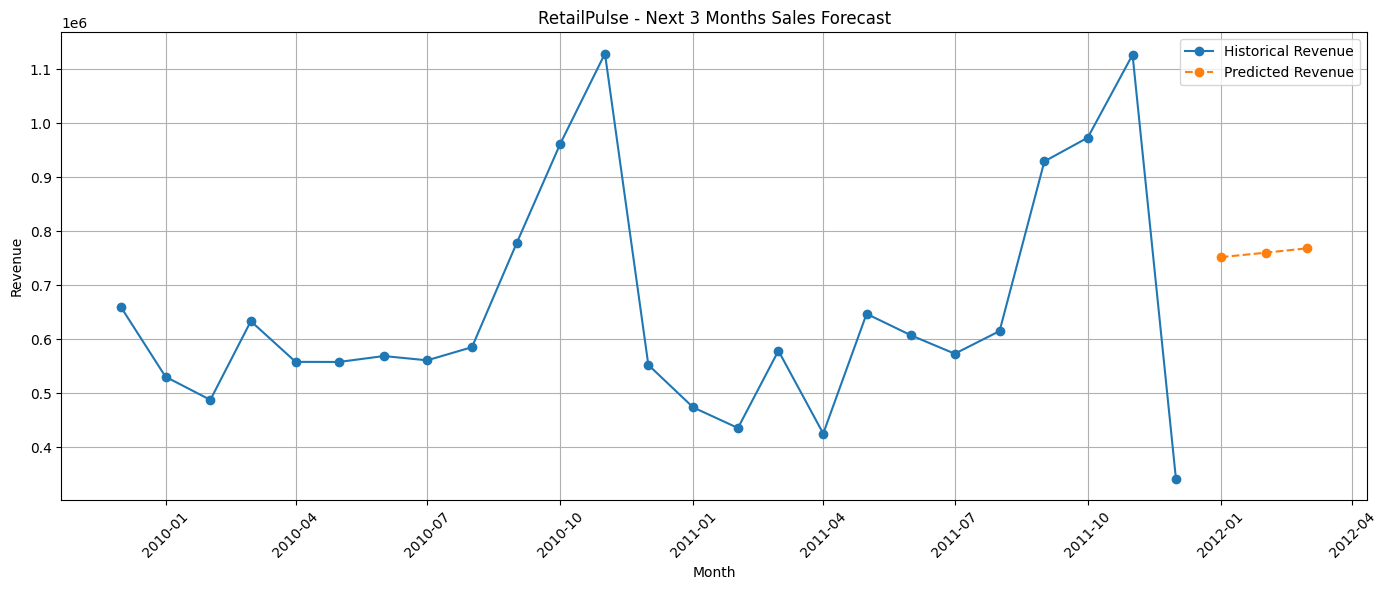


Forecast CSV successfully saved!


In [4]:

# ============================================
# RETAILPULSE - SALES PREDICTION & FORECASTING
# Next 3 Months Sales Forecast
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# 1. Load Dataset
df2 = pd.read_csv("RetailPulse_Cleaned.csv")

# 2. Convert Date Column
df2['InvoiceDate'] = pd.to_datetime(df2['InvoiceDate'])

# 3. Calculate Revenue
df2['Revenue'] = df2['Quantity'] * df2['Price']

# 4. Monthly Revenue
monthly_sales = (
    df2.set_index('InvoiceDate')['Revenue']
    .resample('MS')
    .sum()
    .reset_index()
)

monthly_sales.columns = ['Date', 'Actual_Revenue']

# 5. Check Monthly Data
print("Monthly Sales Data:")
print(monthly_sales.head())

# 6. Prepare Time Series
sales_series = monthly_sales.set_index('Date')['Actual_Revenue']

# 7. Train-Test Split
# Last 3 months for testing
train = sales_series.iloc[:-3]
test = sales_series.iloc[-3:]

# 8. Train Holt-Winters Model
model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal=None,
    initialization_method='estimated'
)

fitted_model = model.fit()

# 9. Predict Test Data
test_predictions = fitted_model.forecast(3)

# 10. Model Evaluation
mae = mean_absolute_error(test, test_predictions)
rmse = np.sqrt(mean_squared_error(test, test_predictions))

actual_sum = test.sum()
if actual_sum != 0:
    mape = np.mean(np.abs((test - test_predictions) / test.replace(0, np.nan))) * 100
else:
    mape = np.nan

print("\nMODEL EVALUATION")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# 11. Train Final Model on Full Data
final_model = ExponentialSmoothing(
    sales_series,
    trend='add',
    seasonal=None,
    initialization_method='estimated'
).fit()

# 12. Forecast Next 3 Months
future_forecast = final_model.forecast(3)

forecast_df = pd.DataFrame({
    'Date': future_forecast.index,
    'Predicted_Revenue': future_forecast.values
})

# 13. Combine Historical and Future Data
historical_df = monthly_sales.copy()
historical_df['Type'] = 'Actual'
historical_df = historical_df.rename(
    columns={'Actual_Revenue': 'Revenue'}
)

forecast_output = forecast_df.copy()
forecast_output['Type'] = 'Forecast'
forecast_output = forecast_output.rename(
    columns={'Predicted_Revenue': 'Revenue'}
)

final_output = pd.concat(
    [historical_df, forecast_output],
    ignore_index=True
)

# 14. Save CSV for Power BI
final_output.to_csv(
    'Sales_Forecast_Predictions.csv',
    index=False
)

# 15. Display Forecast
print("\nNEXT 3 MONTHS SALES FORECAST")
print(forecast_df)

# 16. Total Predicted Revenue
print(
    "\nTotal Predicted Revenue:",
    round(future_forecast.sum(), 2)
)

# 17. Visualization
plt.figure(figsize=(14, 6))

plt.plot(
    sales_series.index,
    sales_series.values,
    label='Historical Revenue',
    marker='o'
)

plt.plot(
    future_forecast.index,
    future_forecast.values,
    label='Predicted Revenue',
    marker='o',
    linestyle='--'
)

plt.title('RetailPulse - Next 3 Months Sales Forecast')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nForecast CSV successfully saved!")
